In [217]:
import pandas as pd

client_train_data = pd.read_csv("data/client_train.csv", low_memory=False)
invoice_train_data = pd.read_csv("data/invoice_train.csv",  low_memory=False)

In [218]:
train_data = client_train_data.merge(invoice_train_data, on="client_id", how = "left", validate="1:m")

<Axes: xlabel='target', ylabel='count'>

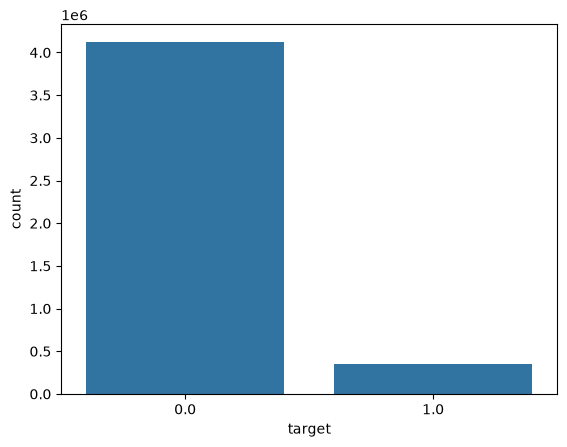

In [219]:
import seaborn as sns
sns.countplot(data=train_data, x="target")
# We see a very imbalanced result

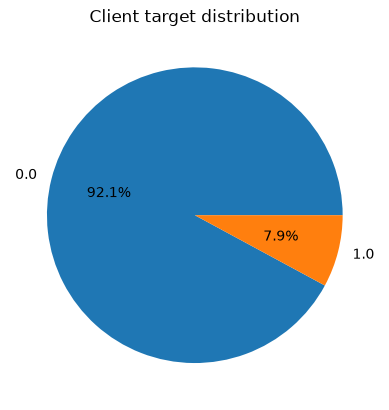

In [220]:
import matplotlib.pyplot as plt

target_counts = train_data["target"].value_counts().sort_index()
plt.pie(
    target_counts,
    labels=target_counts.index,
    autopct="%1.1f%%"
)
plt.title("Client target distribution")
plt.show()

In [221]:
X = train_data[
    ["client_catg", "region", "tarif_type", "counter_type", "reading_remarque",
      "months_number", "counter_coefficient", "counter_number", "consommation_level_1",
      "consommation_level_2", "counter_type", "old_index", "new_index", "creation_date"]
]
y = train_data["target"]

In [222]:
# Make the bill type machine readable
d={"ELEC":0,"GAZ":1}
X = X.loc[:, ~X.columns.duplicated()].copy()
X["counter_type"] = X["counter_type"].map(d)
# 
X['client_catg'] = X['client_catg'].astype(int)
# Get a valid creation date
X["creation_date"] = pd.to_datetime(X["creation_date"]).astype("int64")
#X['disrict'] = X['disrict'].astype(int)
X["n_tarif_types"] = train_data.groupby("client_id")["tarif_type"].transform("nunique")

C:\Users\tapio\AppData\Local\Temp\ipykernel_34400\3138496458.py:8: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  X["creation_date"] = pd.to_datetime(X["creation_date"]).astype("int64")


In [223]:
# If the result is negative, this might indicate a fraud.
X["diff_index"] = X["new_index"] - X["old_index"]
# Ask Peter why I did this
X["consommation_diff"] = (X["new_index"] - X["old_index"]) * X["counter_coefficient"] - (X["consommation_level_1"] + X["consommation_level_2"])

<Axes: >

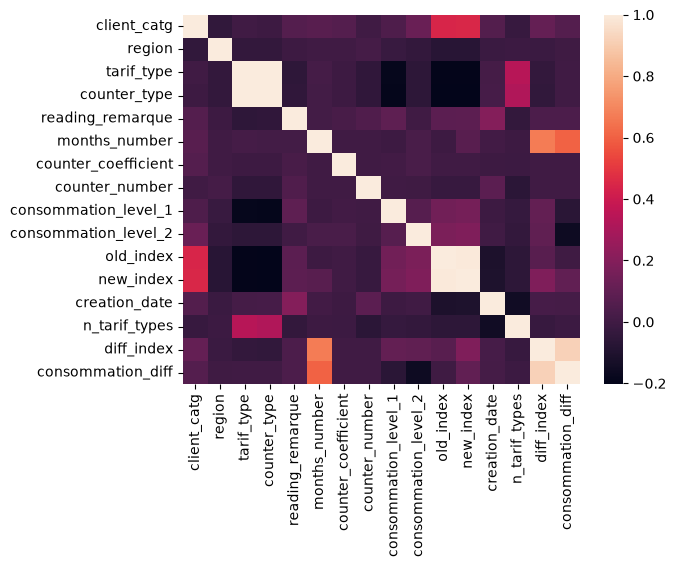

In [224]:
cm = X.select_dtypes(include=["number"]).corr(method="pearson")
sns.heatmap(cm)

In [225]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y, train_size=0.75)

In [226]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
# Convert the date column to a numeric timestamp before scaling
x_scaled = sc.fit_transform(X_train)

In [227]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RandomizedSearchCV

lgbm = LGBMClassifier(n_jobs = 8, random_state=42)
pg = {
    "learning_rate": [0.01, 0.1, 0.2, 1],
    "n_estimators": [10, 100, 200],
    "subsample_for_bin": [10000, 20000, 50000],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

if 0:
    gscv = GridSearchCV(
        estimator=lgbm,
        param_grid=pg,
        n_jobs=8,
        scoring=["roc_auc", "f1"],
        refit="roc_auc",
        cv=cv
    )
else:
    gscv = RandomizedSearchCV(
        estimator=lgbm,
        param_distributions=pg,
        n_jobs=8,
        n_iter=4,
        scoring=["roc_auc", "f1"],
        refit="roc_auc",
        cv=cv
    )

gscv.fit(X_train, y_train)

[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.
[LightGBM] [Info] Number of positive: 264834, number of negative: 3092727
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.084242 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2128
[LightGBM] [Info] Number of data points in the train set: 3357561, number of used features: 16
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.078877 -> initscore=-2.457705
[LightGBM] [Info] Start training from score -2.457705


,estimator,LGBMClassifie...ndom_state=42)
,param_distributions,"{'learning_rate': [0.01, 0.1, ...], 'n_estimators': [10, 100, ...], 'subsample_for_bin': [10000, 20000, ...]}"
,n_iter,4
,scoring,"['roc_auc', 'f1']"
,n_jobs,8
,refit,'roc_auc'
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [228]:
x_test_scaled = sc.fit_transform(X_test)
y_pred = gscv.predict(x_test_scaled)

C:\Users\tapio\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Test AUC: 0.7947


<Axes: >

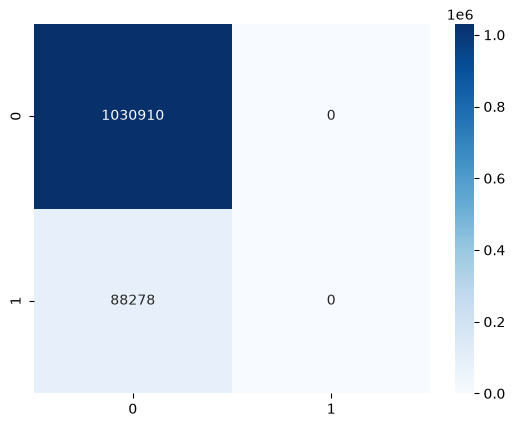

In [229]:
from sklearn.metrics import confusion_matrix, roc_auc_score

print("Test AUC:", round(roc_auc_score(y_test, gscv.predict_proba(X_test)[:, 1]), 4))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")


0.517136744855432

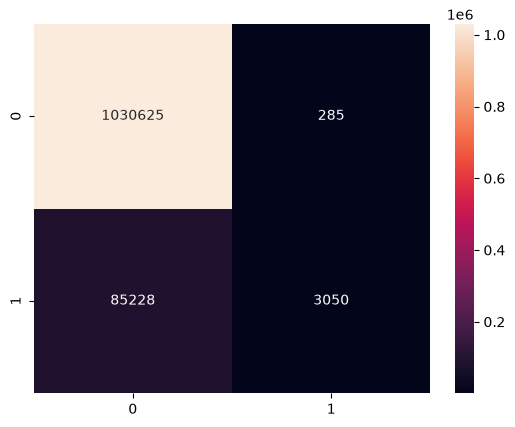

In [ ]:
test_proba = gscv.predict_proba(X_test)[:, 1]
y_pred = (test_proba >= 0.7).astype(int)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=[0, 1], yticklabels=[0, 1])